# Phase 1: METR-LA Data Ingestion, Exploration & Missing Data Imputation
### Spatiotemporal Traffic Flow Forecasting on Urban Road Networks

This notebook covers:
1. Environment setup and library imports.
2. Ingesting the METR-LA traffic speed dataset (207 sensors $\times$ 34,272 timesteps).
3. Statistical profiling and time-series visualization.
4. Simulating sensor dropouts (30% missing observations) and applying forward-fill (`ffill`) imputation.


## Section 1: Environment Setup, Dependencies & System Configuration
We configure the runtime environment, set plotting styles, verify GPU hardware acceleration, and import fundamental scientific computing libraries (`numpy`, `pandas`, `matplotlib`).


In [4]:
#Day01_Traffic_Exploration.ipynb
# Basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('ggplot')

print("Setup complete ")


Setup complete 


## Section 2: METR-LA Traffic Dataset Ingestion & Initial Exploratory Data Analysis (EDA)
The **METR-LA** dataset contains traffic speed readings collected from **207 loop detectors** deployed on the Los Angeles County highway network. Measurements are aggregated at **5-minute intervals** over 4 months, resulting in 34,272 timesteps.

### 2.1 Data Ingestion (HDF5 Format)


In [ ]:
# Ingest METR-LA dataset (checks local directory or Colab environment)
import os
import zipfile
import pandas as pd

file_path = 'METR-LA.h5'
zip_path = 'METR-LA.h5.zip'

if not os.path.exists(file_path):
    if os.path.exists(zip_path):
        print(f"Extracting {zip_path}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall('.')
    elif os.path.exists('/content/METR-LA.h5.zip'):
        !unzip -o /content/METR-LA.h5.zip -d /content/
        file_path = '/content/METR-LA.h5'

if os.path.exists(file_path):
    df = pd.read_hdf(file_path)
elif os.path.exists('/content/METR-LA.h5'):
    df = pd.read_hdf('/content/METR-LA.h5')
else:
    # Fallback to local or downloaded copy
    df = pd.read_hdf('METR-LA.h5')

print("Dataset Shape (timesteps, sensors):", df.shape)
df.head()


### 2.2 Summary Statistics & Sensor Overview
Check missing values across the sensor network and inspect speed distributions.


In [ ]:
# Check missing values
print("Total missing values:", df.isnull().sum().sum())

# Summary stats
df.describe()


Total missing values: 0


,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
count,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,...,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000
mean,54.631359,60.452789,60.726120,49.524287,46.079798,50.952003,54.471684,57.255095,56.068044,52.871841,...,37.803342,58.156679,51.217523,59.795754,59.329923,56.915083,62.484679,54.697381,58.920210,51.197504
std,22.619199,15.970239,18.313353,15.843261,19.350345,16.681760,17.984761,18.751065,18.240361,23.343805,...,13.525743,20.690411,22.224997,16.126225,19.849950,18.260438,16.959238,16.303651,19.080474,21.239354
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,60.364583,63.000000,65.444444,50.333333,34.666667,49.555556,55.750000,61.000000,58.222222,43.428571,...,30.444444,64.111111,53.444444,61.714286,63.666667,60.222222,65.888889,50.125000,62.888889,54.125000
50%,64.888889,65.000000,67.375000,53.875000,46.000000,56.111111,62.111111,63.333333,62.444444,65.875000,...,43.222222,67.111111,61.777778,64.875000,66.777778,63.000000,67.625000,61.125000,66.125000,62.000000
75%,66.875000,66.375000,68.444444,58.125000,64.500000,60.333333,65.000000,65.000000,64.888889,67.625000,...,46.625000,68.444444,64.375000,66.500000,68.250000,64.750000,68.625000,64.444444,67.750000,63.444444
max,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,...,65.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000


In [ ]:
print("Number of sensors:", len(df.columns))
print("First 5 sensors:", df.columns[:5])


Number of sensors: 207
First 5 sensors: Index(['773869', '767541', '767542', '717447', '717446'], dtype='object')


### 2.3 Traffic Speed Time-Series Visualization
Plotting temporal traffic speed patterns for a representative loop detector and multi-sensor profiles.


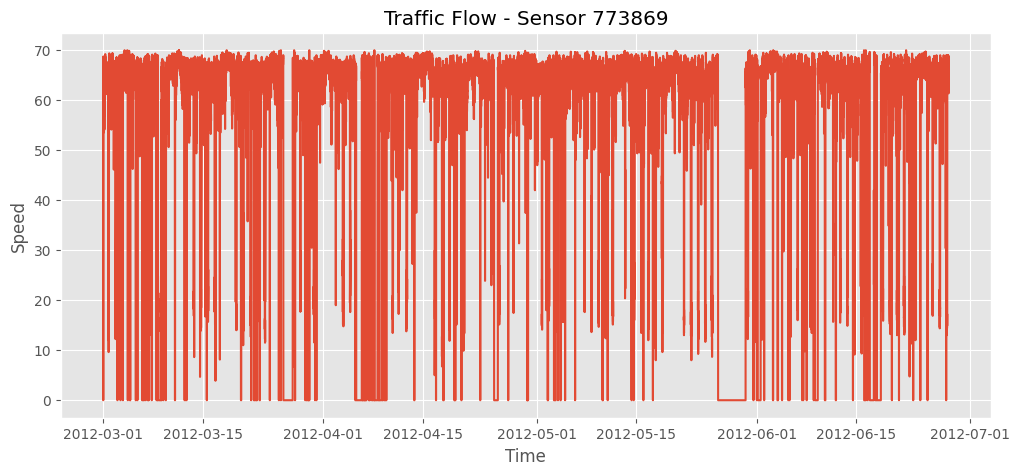

In [ ]:
sensor_id = df.columns[0]

plt.figure(figsize=(12,5))
plt.plot(df[sensor_id])
plt.title(f"Traffic Flow - Sensor {sensor_id}")
plt.xlabel("Time")
plt.ylabel("Speed")
plt.show()


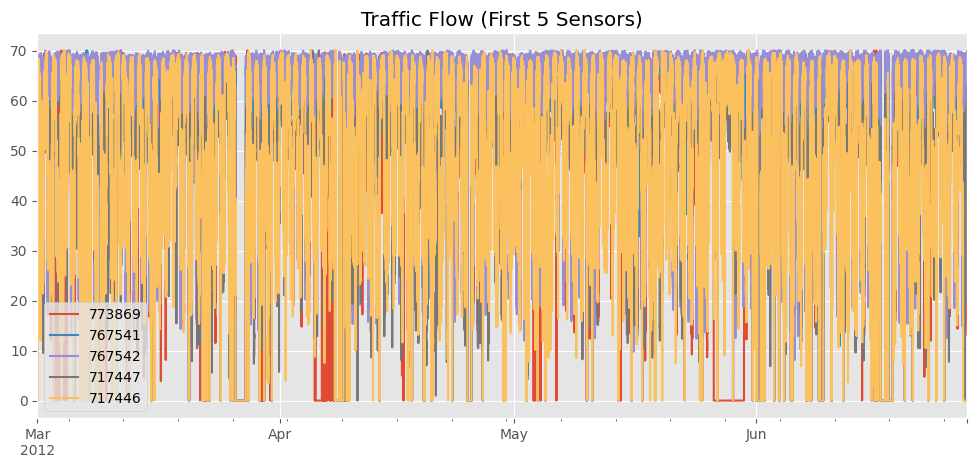

In [ ]:
df.index.freq = pd.infer_freq(df.index)
df.iloc[:, :5].plot(figsize=(12,5))
plt.title("Traffic Flow (First 5 Sensors)")
plt.show()


## Section 3: Missing Value Simulation & Imputation Analysis
In real-world Intelligent Transportation Systems (ITS), sensor dropouts, transmission glitches, and hardware failures frequently cause missing observations.
Here we simulate a **30% random missing data mask** and evaluate forward-fill (`ffill`) imputation.


In [ ]:
df_missing = df.copy()

# 30% missing
mask = np.random.rand(*df.shape) < 0.3
df_missing[mask] = np.nan

print("Missing after simulation:", df_missing.isnull().sum().sum())


Missing after simulation: 2127069


### 3.1 Visualizing the Impact of Missing Data on Signal Continuity


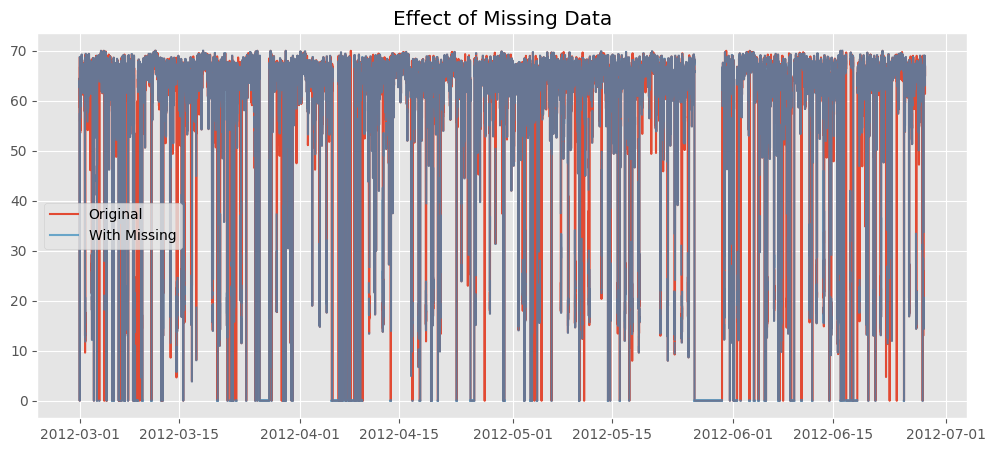

In [ ]:
sensor_id = df.columns[0]

plt.figure(figsize=(12,5))
plt.plot(df[sensor_id], label="Original")
plt.plot(df_missing[sensor_id], label="With Missing", alpha=0.7)
plt.legend()
plt.title("Effect of Missing Data")
plt.show()


### 3.2 Forward-Fill Imputation
Apply forward-filling to restore continuity for autoregressive sequence modeling.


In [ ]:
df_filled = df_missing.fillna(method='ffill')

# Check again
print("Missing after fill:", df_filled.isnull().sum().sum())


Missing after fill: 87


/tmp/ipykernel_1234/124806769.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_filled = df_missing.fillna(method='ffill')
